In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [3]:
file_path = "../data/processed/usd_inr_processed.csv"

df = pd.read_csv(file_path)

df.head()

,date,adj_close,close,high,low,open,volume,daily_return,log_return,intraday_return,price_range,ma_5,ma_10,ma_20,ma_50,volatility_5d,volatility_10d,volatility_20d,momentum_5d,momentum_20d,drawdown,previous_close,change,change_pct,target_5d_volatility
0,2017-03-14,66.170097,66.170097,66.239998,65.727501,66.157501,0,-0.004736,-0.004748,0.000190,0.007745,66.543359,66.656271,66.764476,67.367026,0.041382,0.033958,0.033677,-0.007419,-0.011138,-0.031440,66.485001,-0.314903,-0.473646,0.039754
1,2017-03-15,65.775101,65.775101,65.781700,65.400002,65.764999,0,-0.005969,-0.005987,0.000154,0.005803,66.375139,66.563271,66.714436,67.323632,0.051009,0.042162,0.038520,-0.012626,-0.014987,-0.037222,66.170097,-0.394997,-0.596941,0.038717
2,2017-03-16,65.620499,65.620499,65.628502,65.209999,65.620499,0,-0.002350,-0.002353,0.000000,0.006378,66.146239,66.439520,66.652185,67.273364,0.030074,0.036885,0.038084,-0.017142,-0.018620,-0.039485,65.775101,-0.154602,-0.235046,0.037902
3,2017-03-17,65.404503,65.404503,65.642998,65.349998,65.364998,0,-0.003292,-0.003297,0.000604,0.004480,65.891040,66.295461,66.564170,67.216058,0.023484,0.036223,0.033114,-0.019136,-0.026209,-0.042646,65.620499,-0.215996,-0.329159,0.032120
4,2017-03-20,65.468102,65.468102,65.470001,65.300003,65.468102,0,0.000972,0.000972,0.000000,0.002597,65.687660,66.164970,66.484315,67.167710,0.042170,0.039299,0.034093,-0.015295,-0.023814,-0.041715,65.404503,0.063599,0.097239,0.031607


In [4]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Info:")
df.info()

Shape: (2363, 25)

Columns:
['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'daily_return', 'log_return', 'intraday_return', 'price_range', 'ma_5', 'ma_10', 'ma_20', 'ma_50', 'volatility_5d', 'volatility_10d', 'volatility_20d', 'momentum_5d', 'momentum_20d', 'drawdown', 'previous_close', 'change', 'change_pct', 'target_5d_volatility']

Data Types:
date                     object
adj_close               float64
close                   float64
high                    float64
low                     float64
open                    float64
volume                    int64
daily_return            float64
log_return              float64
intraday_return         float64
price_range             float64
ma_5                    float64
ma_10                   float64
ma_20                   float64
ma_50                   float64
volatility_5d           float64
volatility_10d          float64
volatility_20d          float64
momentum_5d             float64
momentum_20d            fl

In [5]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Date Range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

Date Range:
Start: 2017-03-14 00:00:00
End: 2026-08-31 00:00:00


In [6]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values:
date                    0
adj_close               0
close                   0
high                    0
low                     0
open                    0
volume                  0
daily_return            0
log_return              0
intraday_return         0
price_range             0
ma_5                    0
ma_10                   0
ma_20                   0
ma_50                   0
volatility_5d           0
volatility_10d          0
volatility_20d          0
momentum_5d             0
momentum_20d            0
drawdown                0
previous_close          0
change                  0
change_pct              0
target_5d_volatility    0
dtype: int64

Total Missing Values: 0


In [7]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Dates:", df["date"].duplicated().sum())

Duplicate Rows: 0
Duplicate Dates: 0


In [8]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,2363,2021-12-17 04:56:46.517139200,2017-03-14 00:00:00,2019-09-02 12:00:00,2021-12-15 00:00:00,2024-04-27 12:00:00,2026-08-31 00:00:00,NaN
adj_close,2363.0,77.503905,63.264999,71.337097,75.730003,83.399151,96.8769,8.323611
close,2363.0,77.503905,63.264999,71.337097,75.730003,83.399151,96.8769,8.323611
high,2363.0,77.710969,63.419998,71.542751,76.0625,83.493153,97.0541,8.329135
low,2363.0,77.267149,63.209999,71.09885,75.391899,83.276451,96.459801,8.297709
open,2363.0,77.496776,63.264999,71.309498,75.730003,83.399151,96.8769,8.331106
volume,2363.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
daily_return,2363.0,0.00016,-0.022743,-0.001626,0.000074,0.001822,0.032076,0.003775
log_return,2363.0,0.000153,-0.023005,-0.001627,0.000074,0.00182,0.031573,0.003772
intraday_return,2363.0,0.000104,-0.016207,0.0,0.0,0.0,0.012855,0.001362


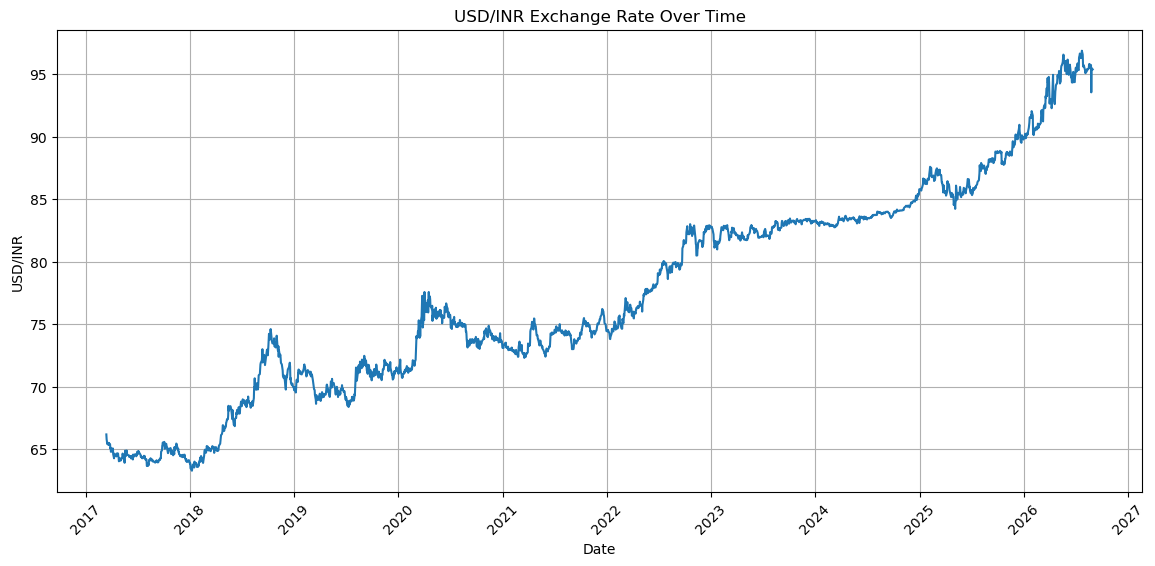

In [9]:
plt.figure(figsize=(14, 6))

plt.plot(df["date"], df["close"])

plt.title("USD/INR Exchange Rate Over Time")
plt.xlabel("Date")
plt.ylabel("USD/INR")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

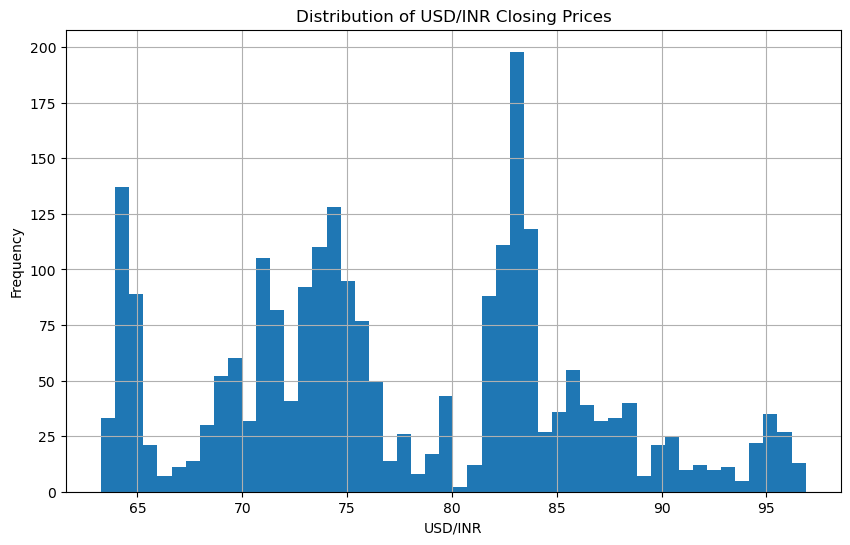

In [10]:
plt.figure(figsize=(10, 6))

plt.hist(df["close"].dropna(), bins=50)

plt.title("Distribution of USD/INR Closing Prices")
plt.xlabel("USD/INR")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

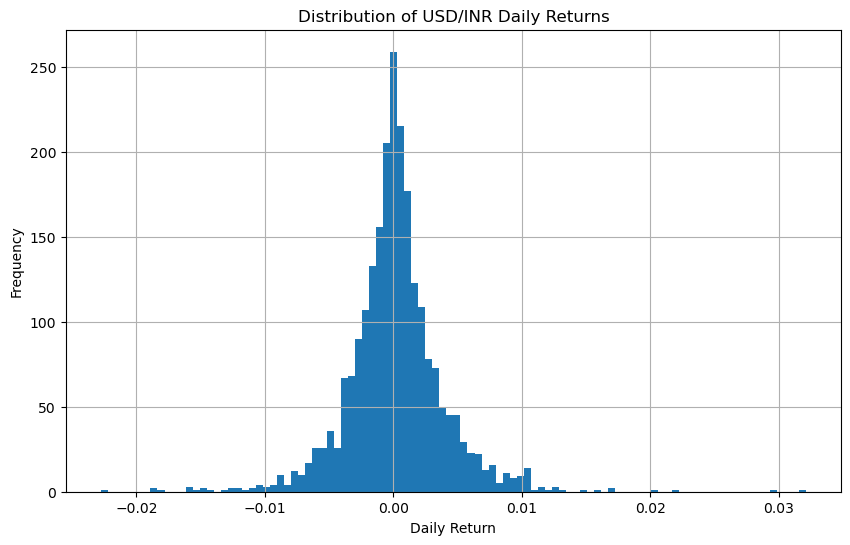

In [11]:
return_col = "daily_return"

plt.figure(figsize=(10, 6))

plt.hist(df[return_col].dropna(), bins=100)

plt.title("Distribution of USD/INR Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

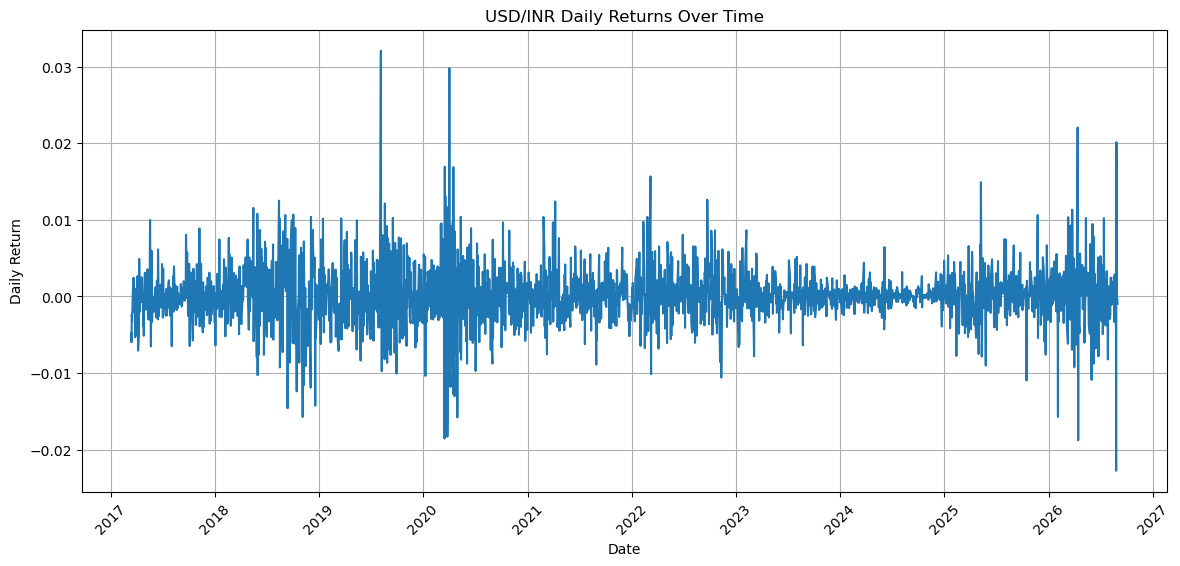

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(df["date"], df["daily_return"])

plt.title("USD/INR Daily Returns Over Time")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [13]:
print("Mean:", df["daily_return"].mean())
print("Median:", df["daily_return"].median())
print("Standard Deviation:", df["daily_return"].std())
print("Minimum:", df["daily_return"].min())
print("Maximum:", df["daily_return"].max())

Mean: 0.00015985520215121903
Median: 7.388062704660747e-05
Standard Deviation: 0.0037754318562204917
Minimum: -0.0227427024557533
Maximum: 0.032076238012807


In [14]:
volatility_columns = [
    col for col in df.columns
    if "volatility" in col.lower()
]

print("Volatility Columns:")
print(volatility_columns)

Volatility Columns:
['volatility_5d', 'volatility_10d', 'volatility_20d', 'target_5d_volatility']


In [15]:
if "volatility_20d" in df.columns:
    volatility_col = "volatility_20d"
elif "volatility_20" in df.columns:
    volatility_col = "volatility_20"
else:
    volatility_col = volatility_columns[-1]

print("Selected Volatility Column:", volatility_col)

Selected Volatility Column: volatility_20d


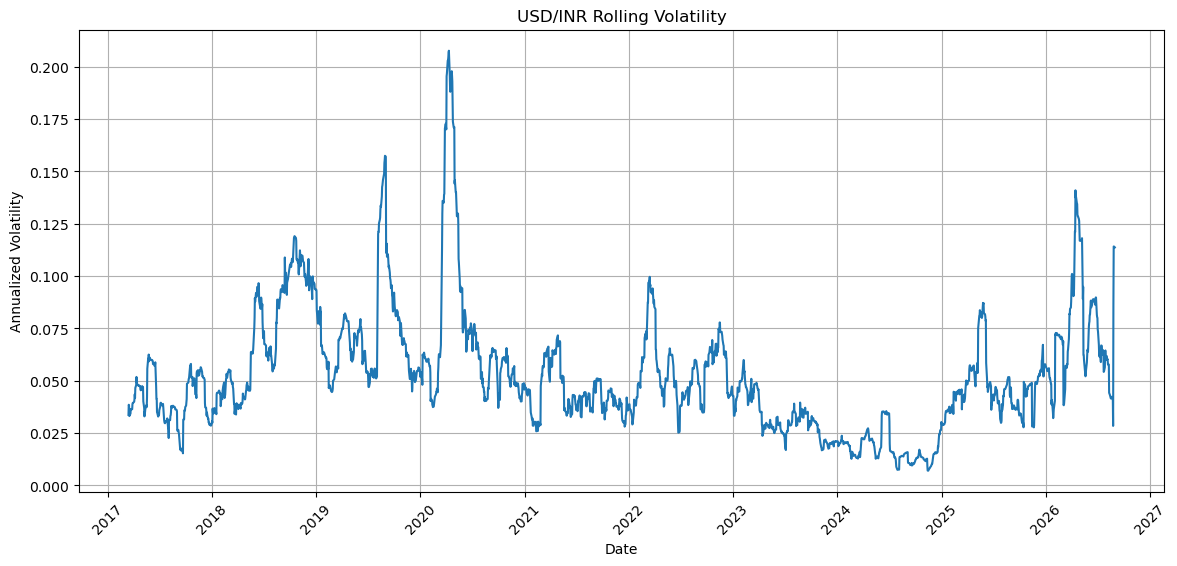

In [16]:
plt.figure(figsize=(14, 6))

plt.plot(df["date"], df[volatility_col])

plt.title("USD/INR Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [17]:
df[volatility_col].describe()

count    2363.000000
mean        0.052274
std         0.028722
min         0.007012
25%         0.035015
50%         0.047153
75%         0.062507
max         0.207677
Name: volatility_20d, dtype: float64

In [18]:
highest_volatility = (
    df[["date", volatility_col]]
    .sort_values(
        by=volatility_col,
        ascending=False
    )
    .head(10)
)

highest_volatility

,date,volatility_20d
746,2020-04-10,0.207677
745,2020-04-09,0.206811
744,2020-04-08,0.204580
743,2020-04-07,0.203143
742,2020-04-06,0.203004
752,2020-04-20,0.197888
741,2020-04-03,0.196779
747,2020-04-13,0.196527
753,2020-04-21,0.195862
740,2020-04-02,0.195490


In [19]:
ma_columns = [
    col for col in df.columns
    if col.startswith("ma_")
]

print("Moving Average Columns:")
print(ma_columns)

Moving Average Columns:
['ma_5', 'ma_10', 'ma_20', 'ma_50']


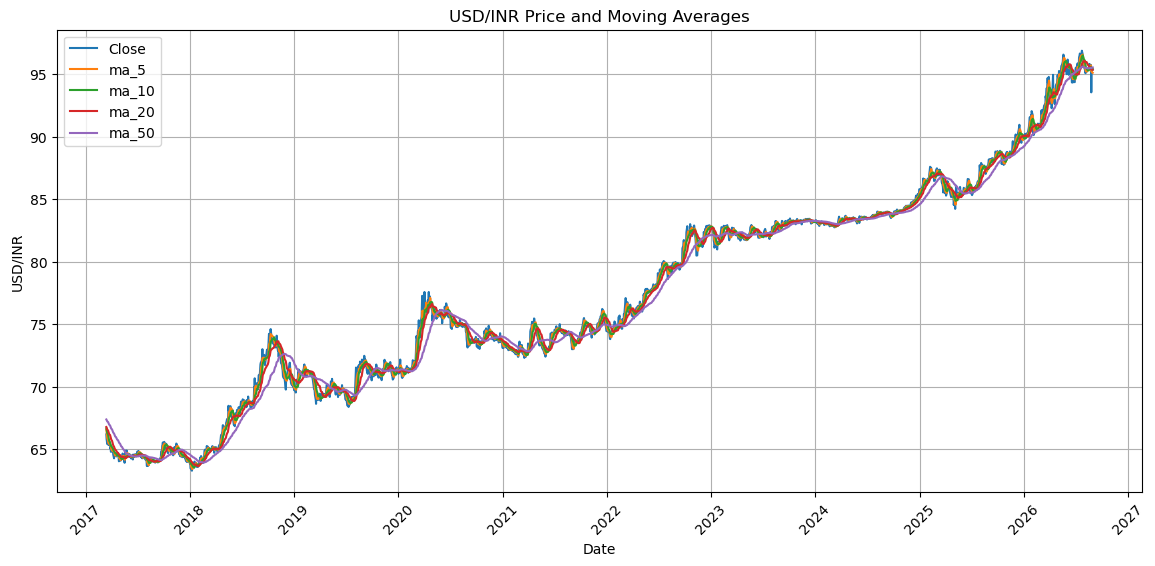

In [20]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["date"],
    df["close"],
    label="Close"
)

for col in ma_columns:
    plt.plot(
        df["date"],
        df[col],
        label=col
    )

plt.title("USD/INR Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("USD/INR")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [21]:
momentum_columns = [
    col for col in df.columns
    if "momentum" in col.lower()
]

print("Momentum Columns:")
print(momentum_columns)

Momentum Columns:
['momentum_5d', 'momentum_20d']


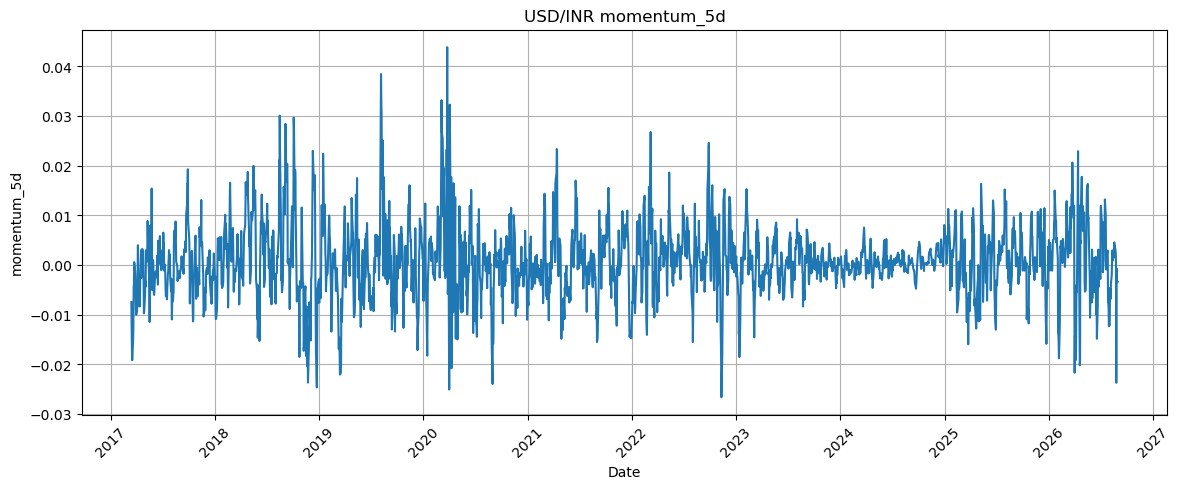

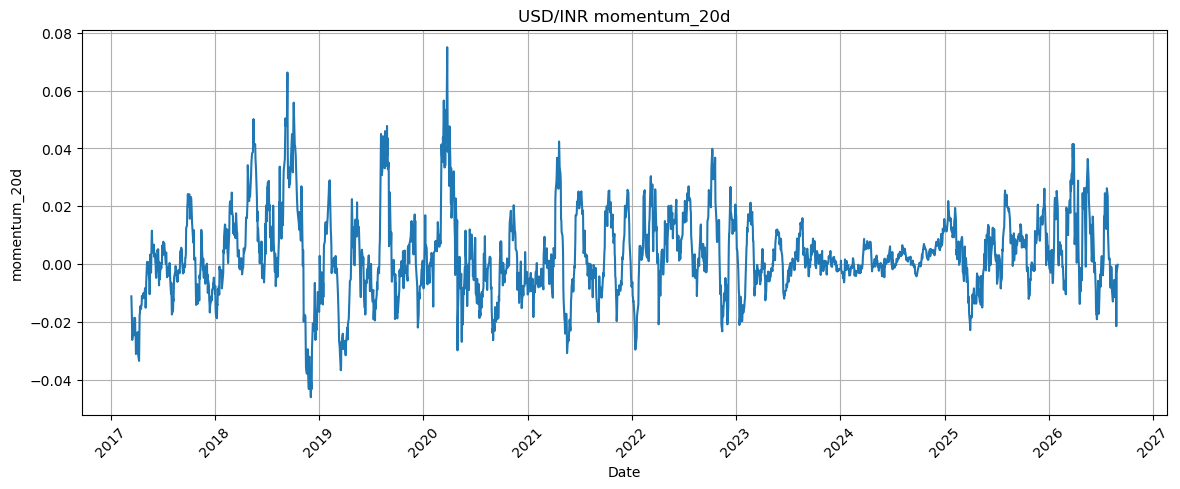

In [22]:
for col in momentum_columns:

    plt.figure(figsize=(14, 5))

    plt.plot(df["date"], df[col])

    plt.title(f"USD/INR {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()

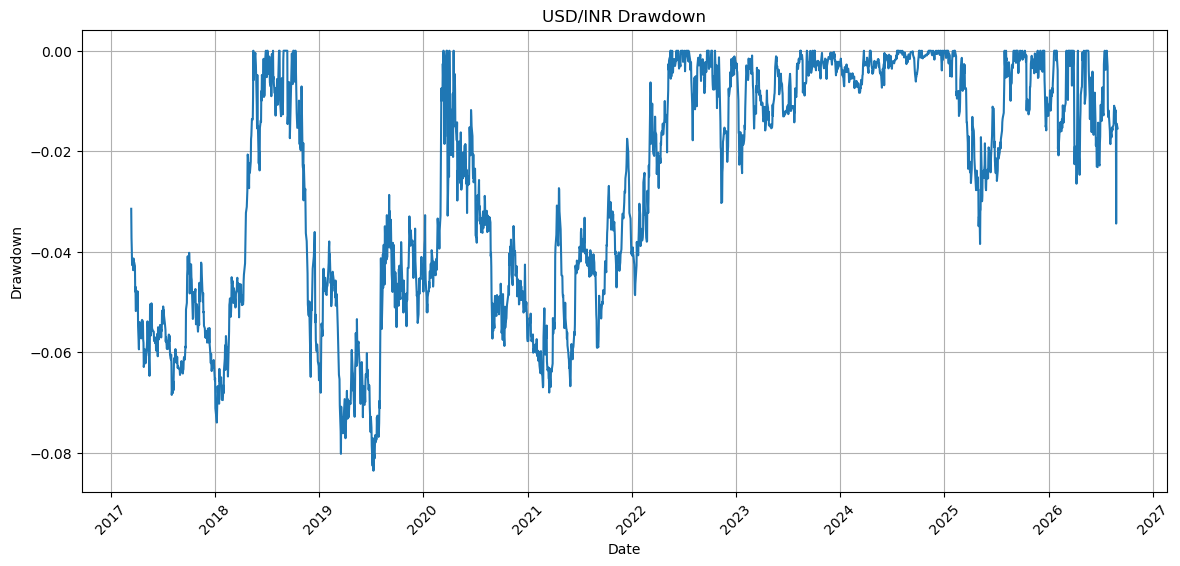

In [23]:
if "drawdown" in df.columns:

    plt.figure(figsize=(14, 6))

    plt.plot(df["date"], df["drawdown"])

    plt.title("USD/INR Drawdown")
    plt.xlabel("Date")
    plt.ylabel("Drawdown")
    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()

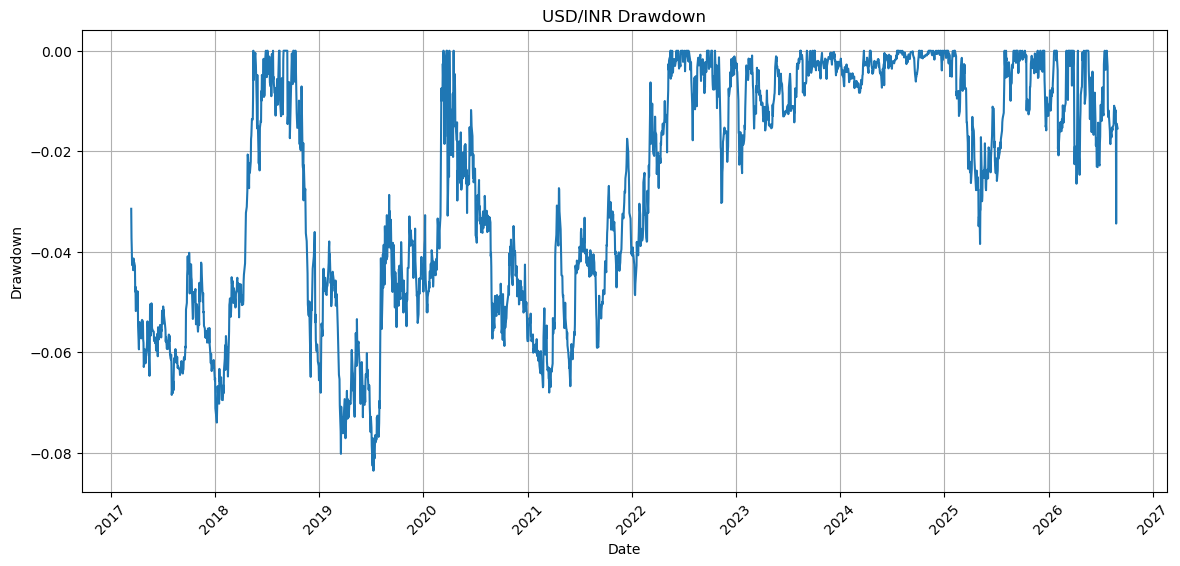

In [24]:
if "drawdown" in df.columns:

    plt.figure(figsize=(14, 6))

    plt.plot(df["date"], df["drawdown"])

    plt.title("USD/INR Drawdown")
    plt.xlabel("Date")
    plt.ylabel("Drawdown")
    plt.xticks(rotation=45)
    plt.grid(True)

    plt.show()

In [25]:
target_col = "target_5d_volatility"

print("Target Column:", target_col)

print("\nTarget Statistics:")
print(df[target_col].describe())

Target Column: target_5d_volatility

Target Statistics:
count    2363.000000
mean        0.050006
std         0.036471
min         0.000936
25%         0.025630
50%         0.041633
75%         0.063389
max         0.261579
Name: target_5d_volatility, dtype: float64


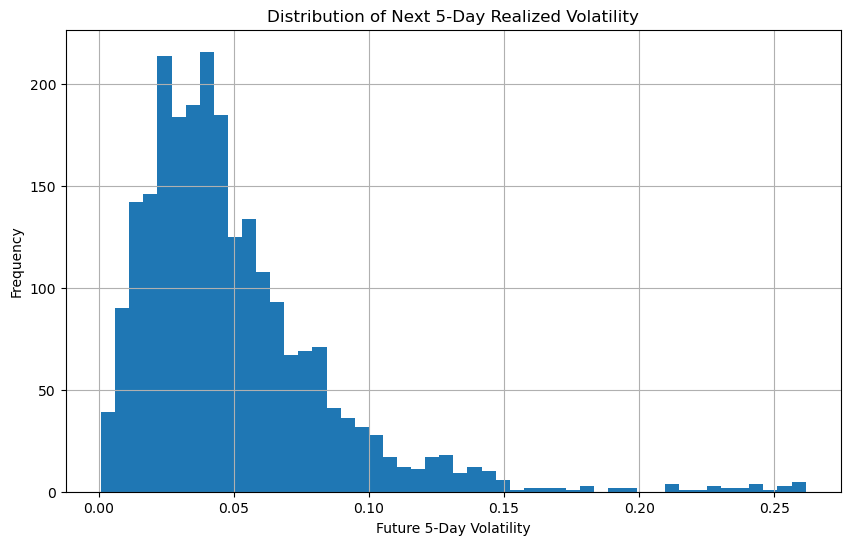

In [26]:
plt.figure(figsize=(10, 6))

plt.hist(
    df[target_col].dropna(),
    bins=50
)

plt.title("Distribution of Next 5-Day Realized Volatility")
plt.xlabel("Future 5-Day Volatility")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

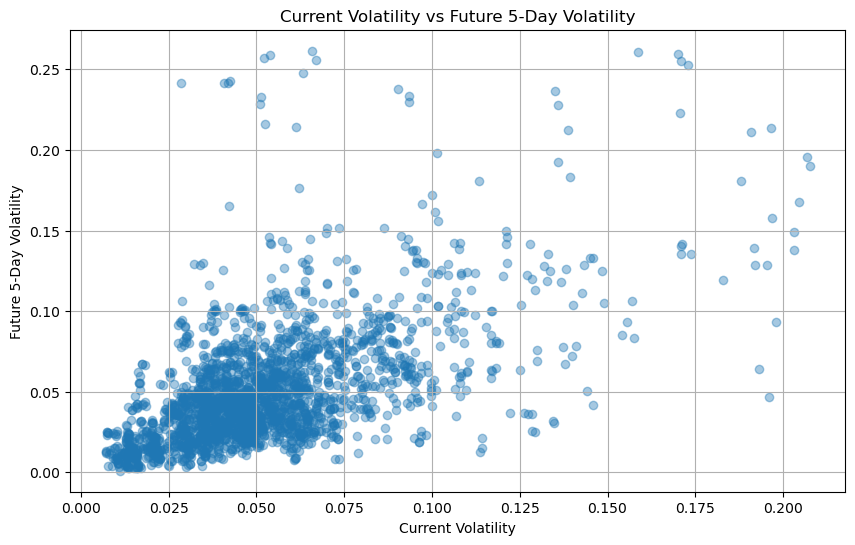

In [27]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df[volatility_col],
    df[target_col],
    alpha=0.4
)

plt.title("Current Volatility vs Future 5-Day Volatility")
plt.xlabel("Current Volatility")
plt.ylabel("Future 5-Day Volatility")
plt.grid(True)

plt.show()

In [28]:
corr = df.corr(numeric_only=True)

target_correlations = (
    corr[target_col]
    .sort_values(ascending=False)
)

target_correlations

target_5d_volatility    1.000000
volatility_20d          0.586331
volatility_10d          0.561609
volatility_5d           0.504779
price_range             0.417496
momentum_20d            0.274347
momentum_5d             0.089657
intraday_return         0.057710
daily_return            0.032775
change_pct              0.032775
log_return              0.031223
change                  0.026473
drawdown               -0.077509
high                   -0.080282
adj_close              -0.089699
close                  -0.089699
open                   -0.090229
previous_close         -0.090685
ma_5                   -0.091948
ma_10                  -0.095411
low                    -0.102340
ma_20                  -0.103937
ma_50                  -0.126377
volume                       NaN
Name: target_5d_volatility, dtype: float64

In [29]:
strongest_features = (
    target_correlations
    .drop(target_col)
    .sort_values(
        key=abs,
        ascending=False
    )
)

print("Strongest Feature Correlations:")
print(strongest_features.head(15))

Strongest Feature Correlations:
volatility_20d    0.586331
volatility_10d    0.561609
volatility_5d     0.504779
price_range       0.417496
momentum_20d      0.274347
ma_50            -0.126377
ma_20            -0.103937
low              -0.102340
ma_10            -0.095411
ma_5             -0.091948
previous_close   -0.090685
open             -0.090229
adj_close        -0.089699
close            -0.089699
momentum_5d       0.089657
Name: target_5d_volatility, dtype: float64


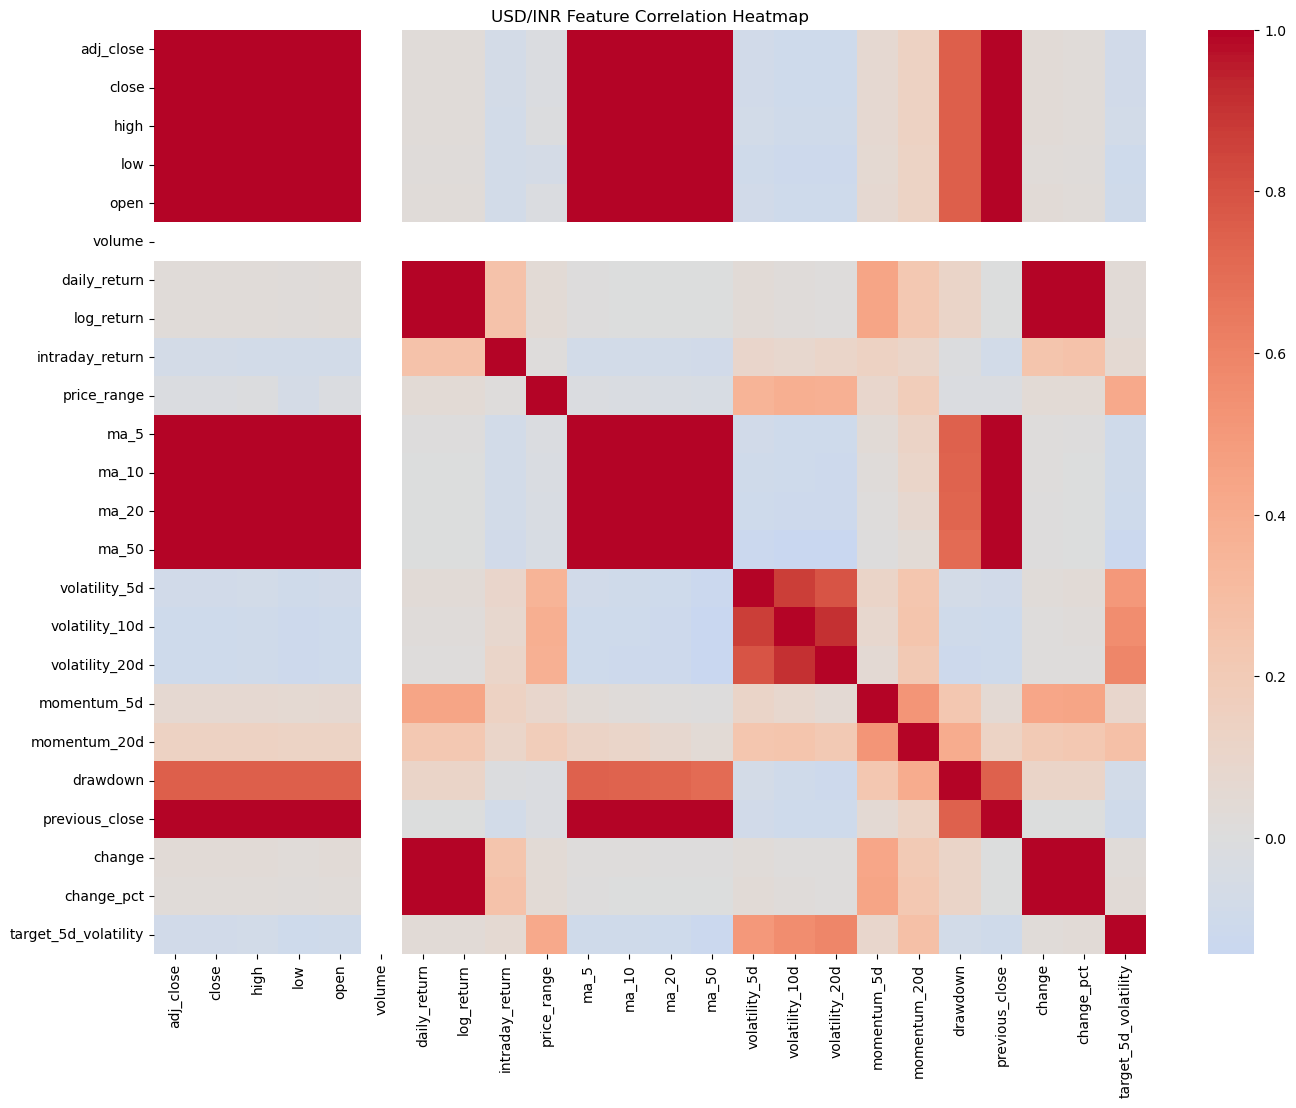

In [30]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("USD/INR Feature Correlation Heatmap")

plt.show()

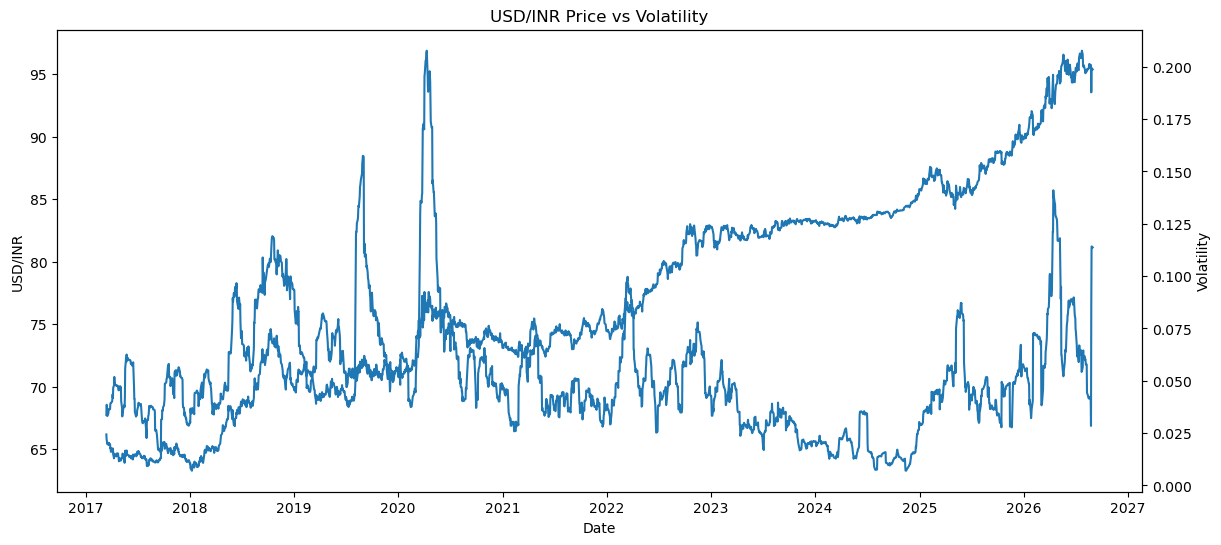

In [31]:
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    df["date"],
    df["close"]
)

ax1.set_xlabel("Date")
ax1.set_ylabel("USD/INR")

ax2 = ax1.twinx()

ax2.plot(
    df["date"],
    df[volatility_col]
)

ax2.set_ylabel("Volatility")

plt.title("USD/INR Price vs Volatility")
plt.xticks(rotation=45)

plt.show()

In [32]:
extreme_returns = (
    df[["date", "daily_return"]]
    .sort_values(
        by="daily_return",
        key=abs,
        ascending=False
    )
    .head(20)
)

extreme_returns

,date,daily_return
571,2019-08-06,0.032076
740,2020-04-02,0.029804
2359,2026-08-26,-0.022743
2262,2026-04-13,0.022050
2360,2026-08-27,0.020142
2264,2026-04-15,-0.018762
727,2020-03-16,-0.018539
735,2020-03-26,-0.018308
728,2020-03-17,0.016927
750,2020-04-16,0.016877


In [33]:
columns_to_check = [
    "close",
    "previous_close",
    "change",
    "change_pct"
]

available_columns = [
    col for col in columns_to_check
    if col in df.columns
]

df[available_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
close,2363.0,77.503905,8.323611,63.264999,71.337097,75.730003,83.399151,96.876900
previous_close,2363.0,77.491677,8.318561,63.264999,71.322998,75.720001,83.394501,96.876900
change,2363.0,0.012228,0.292723,-2.177002,-0.125751,0.005501,0.139149,2.245003
change_pct,2363.0,0.015986,0.377543,-2.274270,-0.162586,0.007388,0.182164,3.207624


In [34]:
print("FINAL DATA QUALITY CHECK")
print("------------------------")

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Dates:", df["date"].duplicated().sum())

print("Date Start:", df["date"].min())
print("Date End:", df["date"].max())

FINAL DATA QUALITY CHECK
------------------------
Rows: 2363
Columns: 25
Missing Values: 0
Duplicate Rows: 0
Duplicate Dates: 0
Date Start: 2017-03-14 00:00:00
Date End: 2026-08-31 00:00:00


In [35]:
summary = {
    "rows": len(df),
    "columns": len(df.columns),
    "date_start": df["date"].min(),
    "date_end": df["date"].max(),
    "missing_values": df.isnull().sum().sum(),
    "duplicate_rows": df.duplicated().sum(),
    "mean_daily_return": df["daily_return"].mean(),
    "daily_return_std": df["daily_return"].std(),
    "max_daily_return": df["daily_return"].max(),
    "min_daily_return": df["daily_return"].min(),
    "mean_volatility": df[volatility_col].mean(),
    "max_volatility": df[volatility_col].max()
}

summary_df = pd.DataFrame([summary])

summary_df

,rows,columns,date_start,date_end,missing_values,duplicate_rows,mean_daily_return,daily_return_std,max_daily_return,min_daily_return,mean_volatility,max_volatility
0,2363,25,2017-03-14,2026-08-31,0,0,0.00016,0.003775,0.032076,-0.022743,0.052274,0.207677


In [36]:
output_path = "../data/processed/usd_inr_eda_summary.csv"

summary_df.to_csv(
    output_path,
    index=False
)

print("EDA summary saved successfully!")
print(output_path)

EDA summary saved successfully!
../data/processed/usd_inr_eda_summary.csv
